# Figure 6 — panels (CD8 T cells: Tpex vs Tex)
Draws the Figure 6 panels from the tables in `data/` (written by `cd8_analysis.ipynb`) → `figures/<panel>.svg`, named by
final panel letter. Figure 6 is assembled in Illustrator (`../../illustrator-figures/Figure6.ai`; panel 6a, the
schematic, lives there). Panels use matplotlib's default font, as published.

In [1]:
import sys

import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sys.path.insert(0, "..")                                # shared modules
import kcore                                            # chromosome strips + paper-wide chromosome palette

LAS_HU = "data/cd8-hu"
LAS_LI = "data/li-2025"
FIG = "figures"
GREEN = "#68B36B"                                      # Tpex (progenitor-exhausted)
PURPLE = "#9C7BB8"                                     # Tex (effector-exhausted)

## Shared setup
The five program sets of 6b and 6c (`data/program_sets.csv`), in one row order for both panels: by the mean over Hu and
Li of the colocalization score −log10 FDR(Tex) − (−log10 FDR(Tpex)) (effector sets on top).

In [2]:
program_sets = pd.read_csv("data/program_sets.csv")


def load_enrichment(las):
    """Enrichment table of the program sets in one dataset; score > 0 = Tex-leaning, < 0 = Tpex-leaning."""
    d = pd.read_csv(f"{las}/pathway_enrichment_filt_20.0.csv").set_index("pathway").loc[program_sets.set_id]
    d["score"] = d.nlog10_fdr_T_EX_EFF - d.nlog10_fdr_T_PEX
    return d


hu = load_enrichment(LAS_HU)
li = load_enrichment(LAS_LI)

In [3]:
keep = list(program_sets.set_id)
clean_name = dict(zip(program_sets.set_id, program_sets.clean))
order = sorted(keep, key=lambda s: (hu.loc[s, "score"] + li.loc[s, "score"]) / 2)
labels = [clean_name[s] for s in order]

## Pathway expression
### Figure 6b — Differentially expressed program gene sets, Tex vs Tpex, Hu (LCMV infection)
GSEA lollipop: stems 0 → NES, dot size = GSEA FDR; purple = up in Tex, green = up in Tpex. Same five sets and row order
as 6c. The ranking is signal-to-noise over the ~3,800-gene Hu DEG list (see the analysis notebook); all five sets have
FDR q = 0 and are drawn at the 0.001 dot size.

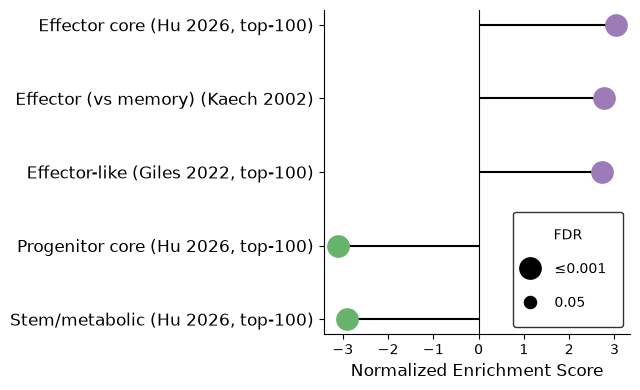

In [4]:
def fdr_to_size(q):
    """Dot size from GSEA FDR q (Fig 1 convention: bigger dot = smaller q)."""
    return np.log(q + 0.005) * -3


gsea_hu = pd.read_csv(f"{LAS_HU}/gsea_hu_tex_vs_tpex.csv").set_index("Term")
program_gsea = gsea_hu.loc[labels]                      # same 5 sets / same row order as 6c
y = np.arange(len(program_gsea))
nes = program_gsea["NES"].values
fdr = pd.to_numeric(program_gsea["FDR q-val"], errors="coerce").clip(lower=0.001).values   # dot size = GSEA FDR
col = np.where(nes >= 0, PURPLE, GREEN)

fig, ax = plt.subplots(figsize=(6.5, 0.6 * len(program_gsea) + 1))
ax.hlines(y=y, xmin=0, xmax=nes, color="black", zorder=1)
for i in range(len(program_gsea)):
    ax.plot(nes[i], y[i], "o", color=col[i], markersize=fdr_to_size(fdr[i]), zorder=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(program_gsea.index, fontsize=12)
ax.tick_params(axis="x", labelsize=10)
ax.set_xlabel("Normalized Enrichment Score", fontsize=12)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.grid(False)
size_handles = []
for q, lab in ((0.001, "≤0.001"), (0.05, "0.05")):
    size_handles.append(mlines.Line2D([], [], color="black", marker="o", linestyle="None",
                                      markersize=fdr_to_size(q), label=f"  {lab}"))
ax.legend(handles=size_handles, title="FDR", loc="lower right", frameon=True, edgecolor="black", borderpad=1.2, labelspacing=1.4,
          handlelength=0, handletextpad=1.2, fontsize=10)
plt.tight_layout()
plt.savefig(f"{FIG}/fig6b_gsea_hu.svg", bbox_inches="tight")
plt.show()

## Pathway colocalization
### Figure 6c — Colocalization of the program gene sets, Hu (LCMV infection) and Li (tumor)
Diverging fold enrichment of state-specific contacts: fold = the set's state-specific share
(`pathway_enrichment_filt_20.0.csv`) ÷ the genome-wide share (`contact_composition_5sets.csv`, Background row); left =
Tpex, right = Tex; coloured if FDR < 0.05 (else grey), `*` = FDR < 0.05, baseline at fold 1; both datasets on one axis.

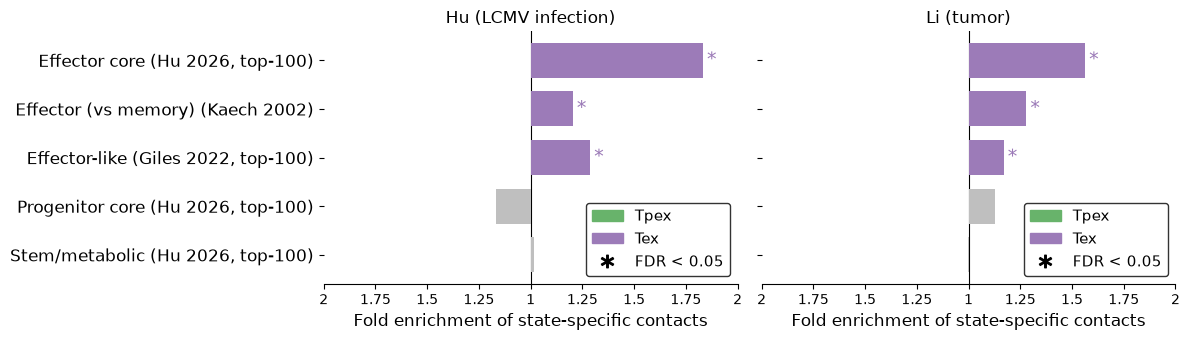

In [5]:
SIG_NLOG10 = -np.log10(0.05)                            # FDR < 0.05 on the -log10 scale
GREY = "#BFBFBF"
X_TICKS = np.arange(0, 2.01, 0.25)
X_TICK_LABELS = ["2", "1.75", "1.5", "1.25", "1", "1.25", "1.5", "1.75", "2"]   # mirrored fold labels around 1
LEGEND_HANDLES = [Patch(color=GREEN, label="Tpex"),
                  Patch(color=PURPLE, label="Tex"),
                  Line2D([], [], marker="$*$", color="k", linestyle="none", markersize=9, label="FDR < 0.05")]


def bg_rates(las):
    """Genome-wide Tex-only and Tpex-only shares (%) of one dataset, from exact counts (not the rounded %)."""
    r = pd.read_csv(f"{las}/contact_composition_5sets.csv").query("set == 'Background (genome)'").iloc[0]
    return 100 * r["Tex_only_n"] / r["N"], 100 * r["Tpex_only_n"] / r["N"]


def colocalization_panel(ax, df, bg, title):
    """Diverging fold-enrichment bars for one dataset (Tpex left, Tex right); bg = genome-wide (Tex, Tpex) shares."""
    bg_tex, bg_tpex = bg
    for i, s in enumerate(order):
        tex_fold = df.loc[s, "pct_T_EX_EFF"] / bg_tex   # fold vs the genome-wide share
        tpex_fold = df.loc[s, "pct_T_PEX"] / bg_tpex
        tex_sig = df.loc[s, "nlog10_fdr_T_EX_EFF"] > SIG_NLOG10
        tpex_sig = df.loc[s, "nlog10_fdr_T_PEX"] > SIG_NLOG10
        ax.barh(i, max(0, tex_fold - 1), left=1, height=0.72, color=PURPLE if tex_sig else GREY, zorder=3)
        ax.barh(i, -max(0, tpex_fold - 1), left=1, height=0.72, color=GREEN if tpex_sig else GREY, zorder=3)
        if tex_sig and tex_fold > 1:
            ax.text(tex_fold + 0.02, i, "*", va="center", color=PURPLE, fontsize=14)
        if tpex_sig and tpex_fold > 1:
            ax.text((2 - tpex_fold) - 0.02, i, "*", va="center", ha="right", color=GREEN, fontsize=14)
    ax.axvline(1, color="k", lw=0.8)
    ax.set(xticks=X_TICKS, yticks=range(len(order)), xlim=(0, 2))
    ax.set_xticklabels(X_TICK_LABELS, fontsize=10)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Fold enrichment of state-specific contacts", fontsize=12)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax.legend(handles=LEGEND_HANDLES, loc="lower right", frameon=True, edgecolor="black", fontsize=11)


bg_hu = bg_rates(LAS_HU)
bg_li = bg_rates(LAS_LI)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 0.5 * len(order) + 1), sharey=True)
colocalization_panel(a1, hu, bg_hu, "Hu (LCMV infection)")
colocalization_panel(a2, li, bg_li, "Li (tumor)")
a1.set_yticklabels(labels, fontsize=12)
plt.tight_layout()
plt.savefig(f"{FIG}/fig6c_colocalization_hu_li.svg", bbox_inches="tight")
plt.show()

## Effector k-cores
### Figure 6d — Tex-specific effector core, Hu (LCMV infection) and Li (tumor)
Each dataset's densest k-core (`data/kcores/`) as a gene × gene contact-state heatmap, genes in genomic order, with
chromosome strips (shared `../kcore.py`); equal-size panels, state legend underneath.

In [6]:
print(pd.read_csv("data/kcores/kcore_summary.csv").to_string(index=False))

dataset  k  n_genes  n_chromosomes  pairs_T_EX_EFF  pairs_T_PEX  pairs_Shared
 cd8-hu  6       35             11             171           24           137
li-2025  6       40             11             186           21           213


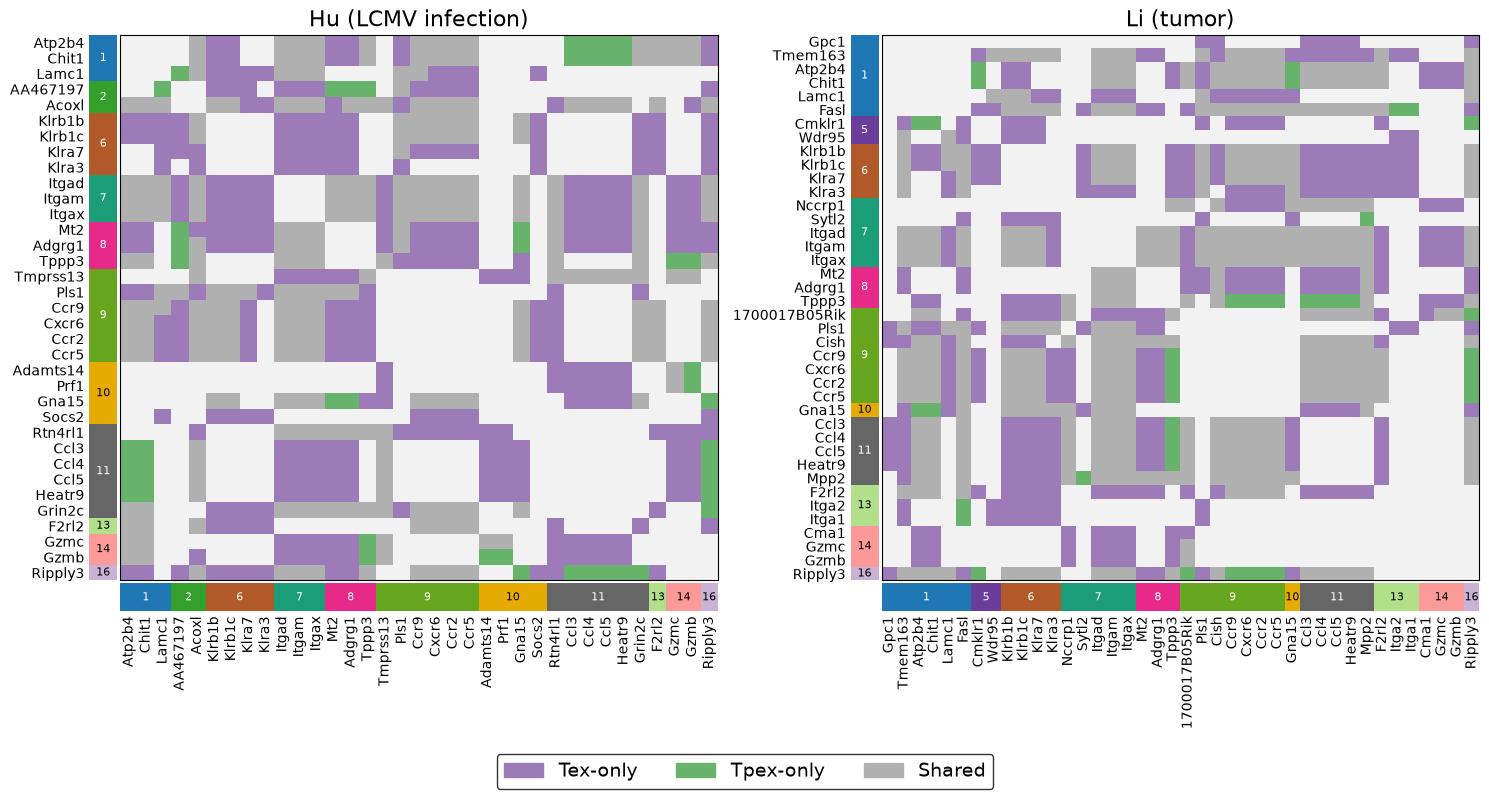

In [7]:
cmap = ListedColormap(["#F2F2F2", PURPLE, GREEN, "#B0B0B0"])   # 0 none | 1 Tex-only | 2 Tpex-only | 3 shared

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))      # equal-size panels
for ax, key, title in [(axes[0], "hu", "Hu (LCMV infection)"),
                       (axes[1], "li", "Li (tumor)")]:
    core_genes = pd.read_csv(f"data/kcores/{key}_effector_genes.csv")
    genes = core_genes.gene.tolist()
    state_matrix = pd.read_csv(f"data/kcores/{key}_effector_states.csv", index_col=0).to_numpy()
    ax.matshow(state_matrix, cmap=cmap, vmin=-0.5, vmax=3.5, aspect="auto")   # stretch to equal-size axes
    fs = 12 if len(genes) < 30 else 10                  # gene-label font (both cores have >= 30 genes -> 10)
    chroms = [int(c.removeprefix("chr")) for c in core_genes.chrom]
    kcore.chrom_strips(ax, genes, chroms, fs, strip_size=0.28)
    ax.set_title(title, fontsize=16)

legend = [Patch(color=PURPLE, label="Tex-only"),
          Patch(color=GREEN, label="Tpex-only"),
          Patch(color="#B0B0B0", label="Shared")]
plt.tight_layout()
fig.legend(handles=legend, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.0), frameon=True, edgecolor="black",
           fontsize=14)
plt.savefig(f"{FIG}/fig6d_effector_cores.svg", bbox_inches="tight")
plt.show()